## *Molecular diffusion mimics "universality classes" of bursty human dynamics*, Moller *et al.* (2025)
## Kinetic Monte Carlo (KMC) simulation

This KMC simulation was developed in order to interpret measurements of tunnel current fluctuations arising from the diffusion of PTCDA molecules (on a Ag(110) surface) under an STM tip [1]. It owes a great to the type of KMC simulation described in Refs. [2] and [4] but goes slightly beyond that approach to incorporate (i) treatment of tip-molecule interactions, and (ii) intermolecular forces. Ansiotropic diffusion, down to the 1D limit, can be treated by modifiying the diffusion coefficients in the *x* and *y* directions. 

The list below includes a number of other important references related to diffusion and bursty dynamics. Ref. [6], in particular, is a readable and helpful description of KMC in the context of tip-adsorbate interactions.

### References
[1] [*Molecular diffusion mimics "universality classes" of bursty human dynamics*](https://muircheartblog.wpcomstaging.com/wp-content/uploads/2025/07/BurstyDiffusion_PNAS_draft_June_06_2025.pdf), M. Moller, P. Rahe, S. Ghaderzadeh, E. Besley, and P. Moriarty (2025) <br>
[2] Susanne Hahne, [PhD thesis](https://osnadocs.ub.uni-osnabrueck.de/bitstream/urn:nbn:de:gbv:700-2014081312705/2/thesis_hahne.pdf), University of Osnabrück (2014)  <br>
[3] S. Hahne, J. Ikonomov, M. Sokolowski, and P. Maas, *Phys. Rev. B* **87** 085409 (2013)<br>
[4] S. Hahne and P. Maas, *J. Phys. Chem. A* **118** 2237 (2014)<br>
[5] C. Schiel, P. Rahe, and P. Maas, *J. Elec. Soc.* **169** 096515 (2022) <br>
[6] X. Wang, Q. Li, and M. C. Tringides, *Phys. Rev. B* **57** 7275 (1998) Effect of tip on diffusion coefficients. <br>
[7] M. L. Lozano and M. C. Tringides, Europhys. Lett. **30** 537 (1995) Important insights into autocorrelation function. <br>
[8] [R. Gomer, Appl. Phys. A 39, 1 (1986)](https://muircheartblog.wpcomstaging.com/wp-content/uploads/2025/07/NB-Gomer-electric-field-from-tip-1985.pdf) Electric field due to tip <br>
[8] J. Ikonomov, P. Bach, R. Merkel, and M. Sokolowski, *Phys. Rev. B* **81** 161412(R) (2010)<br>
[9] See [*Bursty Human Dynamics*](https://arxiv.org/pdf/1803.02580), https://arxiv.org/pdf/1803.02580 for an extensive review.<br>
[10] J. Alstott, E. Bullmore, and D. Plenz, *PLOS ONE* **9** e85777 (2014)<br>

In [1]:
######################
##  Anisotropic KMC ##
##   PJM July 2025  ## 
######################

""" 
The usual suspects...
"""

import os
import time
import numpy as np
import matplotlib.pyplot as plt

from numba import njit
from ipywidgets import Button
from itertools import product
from tqdm.notebook import tqdm
from matplotlib.gridspec import GridSpec
from matplotlib.animation import FuncAnimation
from IPython.display import clear_output, display

"""
Simulation switches and parameters
"""

Animation_ON = True     # Does what it says on the tin. Set this to False to generate, plot, and save residence time and interpeak time distributions.

# The Jupyter Notebook matplotlib backend is notoriously temperamental. I really hope the following works on your installation...

if Animation_ON:
    %matplotlib ipympl   
else:
    %matplotlib inline 

NumMC_per_iter = int(5E6)  # This is the total number of KMC steps per run and controls the largest diffusion length 
                           # that can be reached for a given value of the diffusion coefficient (defined below).

num_iterations = 1000      # Total number of runs, i.e. in this case we would have 1000 x (5E6) KMC steps
num_molecules = 1         

Ll_MC = 5                  # Length of molecule in lattice sites (rows)
Ls_MC = 3                  # Width of molecule in lattice sites (cols)

lattice_dimensions = np.array((50, 50))
monitor_position = lattice_dimensions // 2  # I always position the tip in the centre of the lattice

"""
Physical parameters
"""

D_x = 5000                     # Diffusion coefficient (in nm sqr/s) in x direction
D_y = 0                        # ...you guessed it, diffusion coefficient in y direction.

a0_vec = np.array([0.3, 0.4])  # [row_spacing, col_spacing] Rectangular lattice in this case

kT = 8.6E-5 * 300              # kT

#####################################
# === Intermolecular interactions ===
#####################################

# Not used at the moment. See comments in def simulate_diffusion_step_kMC_with_rates_Morse() function below.

D_e =  0 * kT                  # Well depth. "Switched off" for now.
a_morse = 1.0                  # Inverse interaction length (1/nm) if Dx Dy in nm sqr/s
r_eq = 5                       # Equilibrium separation in units of number of lattice cells

# ===================================
 
all_RTD = []                   # Residence time values
all_ITD = []                   # Interpeak time values
telegraph_signals = []         # Binary signal from monitor site (stream of 0s and 1s)

#rough_tip=False                # Introduced this to modify potential landscape from tip. Ignore.

"""
Numba-enabled functions

Essential for efficient code. Use of Numba precompilation produced a factor of 100 improvement in speed of execution.
However, Numba speed-up comes with key constraints, including globals being a no-no. (It's also a pain to incorporate them in classes.)

"""

@njit
def get_footprint(centre, ldim, Ly, Lx):
    """
    Determine footprint of a molecule..

    Parameters:
    - centre: centre of molecule (lattice sites, (x,y))
    - ldim: Lattice dimensions as (lx, ly).
    - Ly, Lx: Molecule dimensions (length and width). 
    """    
    
    half_Ly = Ly // 2
    half_Lx = Lx // 2
    sites = set()
    for dx in range(-half_Ly, half_Ly + 1):
        for dy in range(-half_Lx, half_Lx + 1):
            x = (centre[0] + dx) % ldim[0]
            y = (centre[1] + dy) % ldim[1]
            sites.add((x, y))
    return sites

@njit
def check_molecule_footprint(centre1, centre2, ldim, Ly, Lx):
    """
    Do two molecules overlap?

    Parameters:
    - centre1, centre2: centres of molecules (lattice sites, (x,y))
    - ldim: Lattice dimensions as (lx, ly).
    - Ly, Lx: Molecule dimensions (length and width). 
    """   
    
    footprint1 = get_footprint(centre1, ldim, Ly, Lx)
    footprint2 = get_footprint(centre2, ldim, Ly, Lx)
    for site in footprint1:
        if site in footprint2:
            return True
    return False

@njit
def check_monitor(molecules, monpos, ldim, Ly, Lx):
    """
    Check if any part of a molecule overlaps with a square monitor region
    centered at monpos, of size (monitor_size x monitor_size).

    Parameters:
    - molecules: Array of molecule centre positions.
    - monpos: Monitor position as (mon_x, mon_y).
    - ldim: Lattice dimensions as (lx, ly).
    - Ly, Lx: Molecule dimensions (length and width).
    - monitor_size: Size of the monitor region (must be odd).

    Returns:
    - True if the monitor region overlaps with any molecule, False otherwise.
    """

    monitor_size=1  # Generally keep this as 1
    
    mon_x, mon_y = monpos
    half_monitor = monitor_size // 2

    for molecule in molecules:
        # Compute bounds of the molecule footprint
        mol_x_min = (molecule[0] - Ly // 2) % ldim[0]
        mol_x_max = (molecule[0] + Ly // 2) % ldim[0]
        mol_y_min = (molecule[1] - Lx // 2) % ldim[1]
        mol_y_max = (molecule[1] + Lx // 2) % ldim[1]

        # Compute bounds of the monitor region
        mon_x_min = (mon_x - half_monitor) % ldim[0]
        mon_x_max = (mon_x + half_monitor) % ldim[0]
        mon_y_min = (mon_y - half_monitor) % ldim[1]
        mon_y_max = (mon_y + half_monitor) % ldim[1]

        # Check for x overlap
        overlap_x = (
            (mol_x_min <= mon_x_max and mon_x_min <= mol_x_max) or
            (mol_x_min > mol_x_max and (mon_x_min <= mol_x_max or mon_x_max >= mol_x_min)) or
            (mon_x_min > mon_x_max and (mol_x_min <= mon_x_max or mol_x_max >= mon_x_min))
        )

        # Check for y overlap
        overlap_y = (
            (mol_y_min <= mon_y_max and mon_y_min <= mol_y_max) or
            (mol_y_min > mol_y_max and (mon_y_min <= mol_y_max or mon_y_max >= mol_y_min)) or
            (mon_y_min > mon_y_max and (mol_y_min <= mon_y_max or mol_y_max >= mon_y_min))
        )

        if overlap_x and overlap_y:
            return True

    return False

@njit
def initialize_molecules(Nmol, ldim, Ly, Lx):
    """
    Initialize molecule positions ensuring no overlaps.
    """
    molecules = np.empty((Nmol, 2), dtype=np.int32)
    count = 0

    while count < Nmol:

        # For 2D diffusion un-comment next line...
        #candidate = np.array([np.random.randint(0, ldim[0]), np.random.randint(0, ldim[1])], dtype=np.int32)
        
        # Next line is for 1D diffusion -- make sure molecule is placed in same column as monitor site! 
        
        candidate = np.array([np.random.randint(0, ldim[0]),ldim[1]//2], dtype=np.int32)
        
        overlap = False
        for i in range(count):
            if check_molecule_footprint(candidate, molecules[i], ldim, Ly, Lx):
                overlap = True
                break

        if not overlap:
            molecules[count] = candidate
            count += 1

    return molecules

@njit
def monitor_distance(mol_pos, monpos, ldim):
    """
    Calculate the distance between the molecular centre and the monitor position,
    considering periodic boundary conditions.

    Parameters:
    - mol_pos: The position of the molecule's centre (x, y).
    - monpos: The monitor position (x, y).
    - ldim: The lattice dimensions.

    Returns:
    - The distance to the monitor position.
    """
    dx = min(abs(mol_pos[0] - monpos[0]), lattice_dims[0] - abs(mol_pos[0] - monpos[0])) * a0_vec[0]
    dy = min(abs(mol_pos[1] - monpos[1]), lattice_dims[1] - abs(mol_pos[1] - monpos[1])) * a0_vec[1]
    return np.sqrt(dx ** 2 + dy ** 2)

@njit
def molecular_distance(pos1, pos2):
    
    center1_x = (pos1[0] + Ll_MC // 2) % lattice_dimensions[0]
    center1_y = (pos1[1] + Ls_MC // 2) % lattice_dimensions[1]
    center2_x = (pos2[0] + Ll_MC // 2) % lattice_dimensions[0]
    center2_y = (pos2[1] + Ls_MC // 2) % lattice_dimensions[1]
    dx = min(abs(center1_x - center2_x), lattice_dimensions[0] - abs(center1_x - center2_x))
    dy = min(abs(center1_y - center2_y), lattice_dimensions[1] - abs(center1_y - center2_y))
    return np.sqrt(dx ** 2 + dy ** 2)

@njit
def precompute_potential(ldim, monpos, kT):
    """
    Precompute the electrostatic potential for all lattice sites relative to the monitor site.

    Parameters:
    - ldim: Lattice dimensions (lx, ly).
    - monpos: Monitor position (x, y).
    - kT: Thermal energy.

    Returns:
    - potential_lattice: A 2D array with the precomputed potential values.
    """
    
    potential_lattice = np.zeros((ldim[0], ldim[1]), dtype=np.float64) # Set up empty lattice for potential

    # See Fig. 1 of R. Gomer, Appl. Phys. A 39, 1–8 (1986) for geometry
    
    z0 = 41.88   # Distance from centre of sphere representing tip to surface
    r_tip = 40   # Radius of curvature of tip
    alpha = 4    # Effective polarisability. Tuned this to adjust potential well depth.
    V = 20*kT    # Bias voltage in units of kT. We had a 0.5 V bias...
    
    #####################################
    V=0          # No tip field for now
    #####################################
    
    for i in range(ldim[0]):
        for j in range(ldim[1]):
            dx = min(abs(i - monpos[0]), ldim[0] - abs(i - monpos[0]))
            dy = min(abs(j - monpos[1]), ldim[1] - abs(j - monpos[1]))
            r = np.sqrt(dx ** 2 + dy ** 2)

            E0 = -V * r_tip * (2 * z0 - r_tip) / (z0 ** 2 * (z0 - r_tip))  # See Gomer paper
            E = E0 * ((1 + (r / z0) ** 2) ** (-3 / 2))                     
            U = 0.5 * alpha * E ** 2
            potential_lattice[i, j] = -U

    return potential_lattice

@njit
def morse_potential(distance, D_e, a, r_e):
    """
    Compute Morse potential energy for a given distance between molecules.
    
    Parameters:
    - distance : float
        Distance between molecules.
    - D_e : float
        Well depth.
    - a : float
        Width parameter.
    - r_e : float
        Equilibrium separation.
    Returns:
    - U : float
        Interaction energy.
    """
    return D_e * (np.exp(-2 * a * (distance - r_e)) - 2 * np.exp(-a * (distance - r_e)))

@njit
def interaction_energy(pos1, molecules, selected_idx, D_e, a, r_e):
    """
    Compute total interaction energy for a molecule at pos1 with all others.
    Parameters:
    - pos1 : (int, int)
        Proposed position of the molecule.
    - molecules : ndarray
        Array of current molecule positions.
    - selected_idx : int
        Index of the molecule being moved (exclude self-interaction).
    Returns:
    - total_U : float
        Total interaction energy.
    """
    total_U = 0.0
    for i in range(molecules.shape[0]):
        if i != selected_idx:
            dist = molecular_distance(pos1, molecules[i])
            total_U += morse_potential(dist, D_e, a, r_e)
    return total_U


@njit
def CalculateRate(pos1, pos2, potential_lattice, molecules, a0_vec, D_x, D_y, lattice_dims):
                            
    """
    Compute KMC hop rate modified by tip potential.

    Parameters:

    pos1, pos2: Current and next position of molecule
    molecules: vector of molecule positions
    a0_vec: lattice constant
    D_x, D_y: diffusion coefficients oin x and y directions
    lattice_dims: lattice dimensions
    """
    
    kT = 8.6E-5 * 300  # Yes, sloppy, because kT is also a global, but see note above re. globals and @njit-decorated functions.
    
    U_current = potential_lattice[pos1[0], pos1[1]]   # Compute potential at current site from pre-defined look-up table
    U_next = potential_lattice[pos2[0], pos2[1]]      # Compute potential at site to which molecule is hopping
    
    deltaU = U_next - U_current                       

    dx = (pos2[0] - pos1[0]) % lattice_dims[0]        # Need to take account of periodic boundary conditions. (Such fun...)
    dy = (pos2[1] - pos1[1]) % lattice_dims[1]

    # Use appropriate diffusion constant (i.e. D_x or D_y) to determine base rate (i.e. rate in absence of tip (and/or intermolecular) potential)
    
    if dx == 1 or dx == lattice_dims[0] - 1:
        base_rate = D_x / (a0_vec[0] ** 2)
    elif dy == 1 or dy == lattice_dims[1] - 1:
        base_rate = D_y / (a0_vec[1] ** 2)
    else:
        base_rate = 0.0

    # As per Wang et al. [PRB 57 7275 (1998)], we simply multiply the base rate by the Boltzmann factor 
    # arising from interaction with tip...

    return base_rate * np.exp(-deltaU / kT)

#######################################################
## Following function is [UNUSED] right now. Ignore. ##
#######################################################

# @njit
# def CalculateRate_with_Morse(pos1, pos2, potential_lattice, molecules, a0_vec, D_x, D_y, lattice_dims,
#                              selected_idx, D_e, a, r_e):
#     """
#     [UNUSED] Compute KMC hop rate with Morse potential for intermolecular interactions. 
#     Not used right now. See comments below.
#     """
    
#     kT = 8.6E-5 * 300 # Yes, sloppy because kT also defined as a global, but see note above re. njit-decorated functions...
    
#     U_current = potential_lattice[pos1[0], pos1[1]]   # Electrostatic potential due to tip at current location
#     U_next = potential_lattice[pos2[0], pos2[1]]      # Electrostatic potential due to tip at next location
#     deltaU_tip = U_next - U_current                   # ΔU
    
#     deltaU_int=0                                     

#     # If we have more than one molecule, sum up intermolecular interaction energies...
    
#     if len(molecules)>1:
#         U_int_current = interaction_energy(pos1, molecules, selected_idx, D_e, a, r_e)
#         U_int_next = interaction_energy(pos2, molecules, selected_idx, D_e, a, r_e)
#         deltaU_int = U_int_next - U_int_current

#     deltaU_total = deltaU_tip + deltaU_int 
    
#     # Note that line above assumes electrostatic potential only due to current molecule interacting with tip. 
#     # We really should sum up all electrostatic interactions. Again, for a single molecule this is not a problem!

#     dx = (pos2[0] - pos1[0]) % lattice_dims[0]   # Need to take account of periodic boundary conditions
#     dy = (pos2[1] - pos1[1]) % lattice_dims[1]   

#     # Which direction is molecule hopping? Use appropriate diffusion constant to determine base rate (i.e. in absence of tip, other molecules)
    
#     if dx == 1 or dx == lattice_dims[0] - 1:
#         base_rate = D_x / (a0_vec[0] ** 2)
#     elif dy == 1 or dy == lattice_dims[1] - 1:
#         base_rate = D_y / (a0_vec[1] ** 2)
#     else:
#         base_rate = 0.0

#     # As per Wang et al. [PRB 57 7275 (1998)], we simply multiply the base rate by the Boltzmann factor 
#     # arising from tip and/or intermolecular interactions...
    
#     return base_rate * np.exp(-deltaU_total / kT)


@njit
def simulate_diffusion_step_kMC_with_rates(molecules, ldim, monpos, lattice_potential, Ly, Lx, a0_vec,
                                                 D_x, D_y, D_e, a, r_e):
    """
    Perform a KMC step.

    Parameters:
    molecules: vector of molecule positions
    ldim: lattice dimensions
    monpos: monitor position
    lattice_potential: pre-computed potential variation due to tip
    Ly, Lx: Molecule dimensions (in numbers of lattice cells)
    a0_vec: lattice constants
    D_x,D_y: diffusion coefficients in x and y directions
    
    [UNUSED] D_e, a, r_e: Parameters related to Morse potential for intermolecular interactions.
    """
    
    num_molecules = molecules.shape[0]
    selected_idx = np.random.randint(0, num_molecules)  # Select a molecule at random
    molecule = molecules[selected_idx]                  # "molecule" is coords of molecule chosen to hop
    directions = [(0, 1), (0, -1), (1, 0), (-1, 0)]     # possible directions on square/rectangular lattice
    rates = np.zeros(4)                                 # rates in each direction  
    total_rate = 0.0                                    # We're going to sum up rates so start with total_rate=0  

    # For KMC, we have to sum up rates in all possible directions (i.e. assuming no overlap of molecules -- rate for this is 0)
    
    for i, direction in enumerate(directions):
        
        # Determine position to which molecule could hop (taking into account periodic boundary conditions)
        
        new_pos = np.array([(molecule[0] + direction[0]) % ldim[0], 
                            (molecule[1] + direction[1]) % ldim[1]])

        overlap = False  # Flag to check for molecular overlap. (Note that Hahne code doesn't check this and just assumes low enough density.)

        for j in range(num_molecules):

            # Check for overlap. Ignore this direction if true...
            if j != selected_idx and check_molecule_footprint(new_pos, molecules[j], ldim, Ly, Lx):
                overlap = True
                break 
        
        if not overlap:
            #rates[i] = CalculateRate_with_Morse(molecule, new_pos, lattice_potential, molecules, a0_vec,
             #                                   D_x, D_y, ldim, selected_idx, D_e, a, r_e)
            
            # Calculate rate via Boltzmann factor...
            rates[i] = CalculateRate(molecule, new_pos, lattice_potential, molecules, a0_vec,
                                                D_x, D_y, ldim)
            total_rate += rates[i]

    if total_rate == 0: # If the total rate is 0, the molecule is blocked due to other surrounding molecules so rate is 0
        return molecules, False, 0.0

    ###########################################################
    ## ...and the following is the guts of the KMC algorithm ##
    ###########################################################
    
    dt = -np.log(np.random.rand()) / total_rate   # Calculate KMC time step on basis of total rate
    r = np.random.rand() * total_rate             # Choose a rate that randomly lies somewhere between [0, total_rate]  

    cumulative = 0.0

    # The following few lines are essentially the Gillespie algorithm (which is very cute)...
    
    for i in range(4):
        cumulative += rates[i]  # The "rates" array contains the rate for each (permissible, i.e. not blocked) direction 
        
        # We add up the rates until we reach (or surpass) our randomly chosen rate, r. This defines which direction we move.
        # Essentially, we have a four segment dial (N, S, E, W). We spin a spinner (i.e. randomly select r) and end up in one of those quadrants...
        
        if cumulative >= r:     
            move = directions[i]
            molecules[selected_idx][0] = (molecule[0] + move[0]) % ldim[0]
            molecules[selected_idx][1] = (molecule[1] + move[1]) % ldim[1]
            break

    # Now check whether any part of molecule covers monitor site...
    monitor_signal = check_monitor(molecules, monpos, ldim, Ly, Lx) 
    
    return molecules, monitor_signal, dt # i.e. current coordinates of molecule(s), binary value for monitor signal, and KMC time step

###############################################################################
## [UNUSED] Ignore following functions to calculate mean square displacement ## 
## , not least because they slow the code to an absolute crawl. (They were   ##
## necessary, however, to determine whether molecular dynamics are diffusive ##
## or sub-diffusive in the context of PTCDA and stretched exponentials...)   ##
###############################################################################

# @njit
# def compute_msd(pos, origin, lattice_dims, a0_vec):
#     dx = min(abs(pos[0] - origin[0]), lattice_dims[0] - abs(pos[0] - origin[0])) * a0_vec[0]
#     dy = min(abs(pos[1] - origin[1]), lattice_dims[1] - abs(pos[1] - origin[1])) * a0_vec[1]
#     return dx ** 2 + dy ** 2

# @njit
# def update_msd_bin(current_time, msd, MSD_bins, MSD_sums, MSD_counts):
#     for i in range(len(MSD_bins) - 1):
#         if MSD_bins[i] <= current_time < MSD_bins[i + 1]:
#             MSD_sums[i] += msd
#             MSD_counts[i] += 1
#             break


"""
#########################################################################
## Define kMC Animation class for, unsurprisingly, animation purposes. ##
## We don't need to use any @njit-decorated functions for animation so ##
## it's much neater to bundle them all together as methods in a class. ##  
#########################################################################

# === Animation Class ===
"""

class kMCAnimation:
    def __init__(self, lattice_dimensions, monitor_position, potential_lattice,
                 molecules, Ll_MC, Ls_MC, a0_vec, D_e, a_morse, r_eq, update_interval=20):
        
        ####################################################
        ## self.D_e, self.a_morse, self.r_eq all [UNUSED] ##
        ####################################################
        
        self.D_e = D_e
        self.a_morse = a_morse
        self.r_eq = r_eq
        
        ##################################################################
        ## Following attributes are just the  variables described above ##
        ##################################################################
        
        self.lattice_dimensions = lattice_dimensions
        self.monitor_position = monitor_position
        self.potential_lattice = potential_lattice
        self.molecules = molecules
        self.Ll_MC = Ll_MC
        self.Ls_MC = Ls_MC
        self.a0_vec = a0_vec

        #######################################
        self.update_interval = update_interval   ## This is specific to the kMCAnimation class and defines the number of kMC steps between each frame
        #######################################

        #############################################
        ## Following attributes relate to graphics ##
        #############################################
        
        self.fig_animation = None                 # Main figure -- lattice + molecules and monitor signal
        self.ax1 = None                           # Comprises two plots (i.e. lattice + molecules, monitor signal)  
        self.ax2 = None
        self.molecule_patches = []                # Rectangle(s) to represent molecule(s)
        self.signal_line = None                   # Monitor signal graphic (binary)
        self.telegraph_signals = []               # Monitor signal itself    
        self.ani = None

    def initialise_patches(self):
        """
        Initialise graphics -- put rectangular molecules on lattice grid
        """
        
        self.fig_animation = plt.figure(figsize=(6, 5))
        gs = GridSpec(2, 1, height_ratios=[4, 1])
        self.ax1 = self.fig_animation.add_subplot(gs[0])

        mon_x_real = self.monitor_position[1] * self.a0_vec[1]
        mon_y_real = self.monitor_position[0] * self.a0_vec[0]
        self.ax1.plot(mon_x_real, mon_y_real, 'r.', markersize=10, alpha=0.5)

        # Draw rectangular grid
        x_max = self.lattice_dimensions[1] * self.a0_vec[1]  # total width
        y_max = self.lattice_dimensions[0] * self.a0_vec[0]  # total height
        
        # Vertical lines (constant x, vary y)
        for j in range(self.lattice_dimensions[1] + 1):
            x = j * self.a0_vec[1]
            self.ax1.plot([x, x], [0, y_max], color='gray', linewidth=0.3, alpha=0.5)
        
        # Horizontal lines (constant y, vary x)
        for i in range(self.lattice_dimensions[0] + 1):
            y = i * self.a0_vec[0]
            self.ax1.plot([0, x_max], [y, y], color='gray', linewidth=0.3, alpha=0.5)


        self.ax1.set_xlim(0, self.lattice_dimensions[1] * self.a0_vec[1])
        self.ax1.set_ylim(0, self.lattice_dimensions[0] * self.a0_vec[0])
        
        self.ax1.set_aspect('equal')  # Enforces true scale ratio -- this was an absolute pig to get right.
        
        self.ax1.set_aspect(self.a0_vec[1] / self.a0_vec[0])
        self.ax1.axis('off')

        half_Ll = self.Ll_MC // 2  # Define molecule centre. Good idea to work with molecules that are an odd number of lattice cells 
        half_Ls = self.Ls_MC // 2  # in each direction so as to preserve symmetry.

        # Draw the molecule(s) on the lattice...
        
        for m in self.molecules:
            for dx in range(-half_Ll, half_Ll + 1):
                for dy in range(-half_Ls, half_Ls + 1):
                    x = (m[1] + dy) % self.lattice_dimensions[1]
                    y = (m[0] + dx) % self.lattice_dimensions[0]
                    x_real = x * self.a0_vec[1]
                    y_real = y * self.a0_vec[0]
                    patch = plt.Rectangle((x_real, y_real), self.a0_vec[1], self.a0_vec[0], color='cornflowerblue', alpha=0.8)
                    self.ax1.add_patch(patch)
                    self.molecule_patches.append(patch)

        self.ax2 = self.fig_animation.add_subplot(gs[1])
        self.ax2.set_xlim(0, 100)
        self.ax2.set_ylim(-0.1, 1.1)
        self.ax2.set_aspect(12, adjustable='box')
        self.ax2.set_xticks([])
        self.ax2.set_xlabel("Time (MC steps)")
        self.ax2.set_ylabel("Monitor")
        self.signal_line, = self.ax2.plot([], [], 'b.-')
    
    def update(self, frame):
        """
        Update animation -- move molecule(s) on lattice and append new value (0 or 1) to monitor signal plot.
        This does all the work when it comes to the animation code.
        """
        
        for _ in range(self.update_interval):

            # Update molecular positions and monitor signal following KMC step...
            
            self.molecules, monsig, _ = simulate_diffusion_step_kMC_with_rates(
            self.molecules, self.lattice_dimensions, self.monitor_position,
            self.potential_lattice, self.Ll_MC, self.Ls_MC, self.a0_vec,
            D_x, D_y, D_e, self.a_morse, self.r_eq
            )
        
        self.telegraph_signals.append(1 if monsig else 0)  # Binary monitor signal

        # Have a scrolling monitor signal display...
        
        if len(self.telegraph_signals) > 100:
            self.telegraph_signals.pop(0)
        self.signal_line.set_data(np.arange(len(self.telegraph_signals)), self.telegraph_signals)

        # Erase molecule(s) from previous position(s)... 
        
        for patch in self.molecule_patches:
            patch.remove()
        self.molecule_patches.clear()

        # ...before redrawing it/them at new position(s):
        
        half_Ll = self.Ll_MC // 2
        half_Ls = self.Ls_MC // 2
        for m in self.molecules:
            for dx in range(-half_Ll, half_Ll + 1):
                for dy in range(-half_Ls, half_Ls + 1):
                    x = (m[1] + dy) % self.lattice_dimensions[1]
                    y = (m[0] + dx) % self.lattice_dimensions[0]
                    x_real = x * self.a0_vec[1]
                    y_real = y * self.a0_vec[0]
                    patch = plt.Rectangle((x_real, y_real), self.a0_vec[1], self.a0_vec[0], color='cornflowerblue', alpha=0.8)
                    self.ax1.add_patch(patch)
                    self.molecule_patches.append(patch)

        return self.molecule_patches + [self.signal_line] 

    def run(self):
        """
        Basically just a wrapper for FuncAnimation(), the low(ish) level animation function
        """
        
        self.initialise_patches()
        self.ani = FuncAnimation(
            self.fig_animation, self.update, blit=True, interval=0.1, cache_frame_data=False
        )
        plt.tight_layout()
        plt.show()

# ========================== End of kMCAnimation class definitions =====================================

def calculate_times(all_times, telegraph_signal):
    """
    Calculate residence time distribution (RTD) and interpeak time distribution (ITD) from array of times and the telegraph signal.
    """
    
    residence_times = []
    interpeak_times = []

    # Convert lists to np arrays otherwise nothing bloody works...
    
    all_times = np.array(all_times)
    telegraph_signal = np.array(telegraph_signal)

    # The following line of (uncommented!) code does a lot of heavy lifting. Detects where signal changes, either from 0 to 1 or from 1 to 0...
    # 
    # (i) np.diff() computes differences. 
    # So if telegraph_signal doesn't change we have a 0; if it changes from 0 to 1, we have 1; and from 1 to 0, we have -1
    #
    # (ii) Then the !=0 bit returns a boolean array showing whether a change occurred e.g. (True, False, False, True etc...)
    #
    # (iii) The np.where()[0] bit finds the indices where this occurred. The [0] here is a massive pain and has nothing to do with the logic.
    # It's because the array that's returned is a damned tuple and we need only one element. So just Python syntax.
    #
    # (iv) ...and finally, we need the +1 because we want where the transition has happened.
    
    transition_indices = np.where(np.diff(telegraph_signal) != 0)[0] + 1 

    # The following lines are also perhaps not the most intuitive.
    # Essentially, if the size of the transitions array is 0, then no changes have occurred.
    # If the telegraph (i.e. monitor) signal was 1 at the start then it means that the total time spent in that state is purely residence time.
    # But if the monitor signal was 0 at the start then it means the total time spent in that state is purely interpeak time.
    
    if transition_indices.size == 0:
        if telegraph_signal[0] == 1:
            residence_times.append(all_times[-1] - all_times[0])
        else:
            interpeak_times.append(all_times[-1] - all_times[0])
        return np.array(residence_times), np.array(interpeak_times)

    # Following lines are to account for the start and end of the signal. These took a frustratingly long time to get right.
    if transition_indices[0] != 0:
        transition_indices = np.insert(transition_indices, 0, 0)
    if transition_indices[-1] != len(telegraph_signal):
        transition_indices = np.append(transition_indices, len(telegraph_signal))

    # Then calculate times spent in each state for a non-zero transitions array...
    
    for i in range(len(transition_indices) - 1):
        start = transition_indices[i]
        end = transition_indices[i + 1]
        time_spent = all_times[end - 1] - all_times[start]
        if telegraph_signal[start] == 1:
            residence_times.append(time_spent)
        else:
            interpeak_times.append(time_spent)

    return np.array(residence_times), np.array(interpeak_times)  #...and return only the residence times and the interpeak times

##########################
## Main Simulation Loop ##
##########################

def run_simulation(potential_lattice):
    """
    This function brings it all together. All the other functions do the work. This just gets them to play nicely with each other!
    """

    # Logarithmic binning for RTD and ITD 
    RTDbins = np.logspace(np.log10(1E-6), np.log10(1E-2), 201)
    ITDbins = np.logspace(-6, 2, 201)

    # total_RTD_counts and total_ITD_counts hold the RTD and ITD histogram data
    total_RTD_counts = np.zeros(200)
    total_ITD_counts = np.zeros(200)

    MeanRTD_total=0  # Mean residence time, mean interpeak time, and the standard deviation of the ITD (across all KMC runs)
    MeanITD_total=0
    SigmaITD_total=0
    
    Bmin=10 # Used for calculation of max and min burstiness. In the end this was pointless because the B value in and of itself
    Bmax=0  # is really not a good metric.     

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 6))

    for iteration in range(num_iterations): 
        # num_iterations is the total number of KMC runs (each of, say 5E6 steps, or however it's defined right at the start of the code)
        molecules = initialize_molecules(num_molecules, lattice_dimensions, Ll_MC, Ls_MC)
        current_time = 0.0
        all_times = []
        telegraph_signal = []

        for _ in tqdm(range(NumMC_per_iter), desc=f"Iteration {iteration+1}/{num_iterations}", ncols=500):  # Use a tqdm progress bar
            molecules, signal, dt = simulate_diffusion_step_kMC_with_rates(
            molecules, lattice_dimensions, monitor_position, potential_lattice,
            Ll_MC, Ls_MC, a0_vec, D_x, D_y,
            D_e, a_morse, r_eq
            )
            current_time += dt
            all_times.append(current_time)
            telegraph_signal.append(1 if signal else 0)
        
        try:
            RTD, ITD = calculate_times(all_times, telegraph_signal)
        
            if (
                RTD.size == 0 or ITD.size == 0 or
                np.any(np.isnan(RTD)) or np.any(np.isnan(ITD)) or
                np.any(np.isinf(RTD)) or np.any(np.isinf(ITD))
            ):
                print(f"Iteration {iteration} skipped: invalid RTD/ITD values.")
                continue
        
            RTD_counts, _ = np.histogram(RTD, bins=RTDbins, density=True)
            ITD_counts, _ = np.histogram(ITD, bins=ITDbins, density=True)
        
            if np.any(np.isnan(RTD_counts)) or np.any(np.isnan(ITD_counts)):
                print(f"Iteration {iteration} skipped: invalid histogram output.")
                continue
        
        except Exception as e:
            print(f"Iteration {iteration} failed with error: {e}")
            continue

        all_RTD.extend(RTD)
        all_ITD.extend(ITD)
        
        total_RTD_counts += RTD_counts
        total_ITD_counts += ITD_counts

        MC_RTD_times = 0.5 * (RTDbins[:-1] + RTDbins[1:]) # Mid-points of bins!
        MC_ITD_times = 0.5 * (ITDbins[:-1] + ITDbins[1:])

        # Save all RTD and ITD data every 10 iterations...
        
        if (iteration + 1) % 10 == 0:
            np.savetxt("RTD.txt", all_RTD,delimiter=',')
            np.savetxt("ITD.txt", all_ITD,delimiter=',')
            print(f"[Checkpoint] Saved all_RTD.txt and all_ITD.txt at iteration {iteration + 1}")
        
        ##########################################
        ## Calculate mean, sigma, burstiness... ##
        ##########################################
        
        MeanRTD = np.mean(RTD)
        MeanITD = np.mean(ITD)
        MeanRTD_total+=MeanRTD
        MeanITD_total+=MeanITD
        MeanRTD_av=MeanRTD_total/(iteration+1)
        MeanITD_av=MeanITD_total/(iteration+1)

        SigmaITD=np.std(ITD)
        SigmaITD_total+=SigmaITD
        SigmaITD_av=SigmaITD_total/(iteration+1)
        
        B_run = (SigmaITD - MeanITD) / (SigmaITD + MeanITD)
        B_av= (SigmaITD_av - MeanITD_av)/(SigmaITD_av + MeanITD_av)

        if B_run < Bmin:
            Bmin=B_run

        if B_run>Bmax:
            Bmax=B_run
        
        TotalTime=np.sum(all_RTD)+np.sum(all_ITD)
        ProbTimes=np.sum(all_RTD)/TotalTime

        ax1.clear()
        ax2.clear()
        ax1.scatter(MC_RTD_times, total_RTD_counts / (iteration + 1), marker='o', facecolors='none', edgecolors='green', s=10, linewidths=1.0, label="RTD")
        ax2.scatter(MC_ITD_times, total_ITD_counts / (iteration + 1), marker='o', facecolors='none', edgecolors='orange', s=10, linewidths=1.0, label="ITD", color='orange')

        ax1.set_xscale('log')
        ax1.set_yscale('log')
        ax2.set_xscale('log')
        ax2.set_yscale('log')
        ax1.set_title("Residence Time Distribution")
        ax2.set_title("Interpeak Time Distribution")
        ax1.set_xlabel("t")
        ax2.set_xlabel("t")
        ax1.set_ylabel("\u03A8(t)")
        ax2.set_ylabel("\u03A8(t)")
        ax1.grid(True, which='both', linestyle='--')
        ax2.grid(True, which='both', linestyle='--')

        plt.tight_layout()
        clear_output(wait=True)
        
        print("N_RTD. This run:",len(RTD), " All runs:", len(all_RTD))
        print("N_ITD. This run:",len(ITD), " All runs:", len(all_ITD))
        print(f"Mean residence time this run: {MeanRTD:0.3e}")
        print(f"Mean residence time averaged over all runs: {MeanRTD_av:0.3e}")
        print("-------------------------------------------------------")
        print(f"Mean interpeak time this run: {MeanITD:0.1e}")
        print(f"Mean interpeak time averaged over all runs: {MeanITD_av:0.1e}")
        print(f"Std of interpeak times this run: {SigmaITD:0.1e}")
        print(f"Std of interpeak times averaged over all runs: {SigmaITD_av:0.1e}")
        print("-------------------------------------------------------")
        print(f"Burstiness this run: {B_run:0.2f}")
        print(f"Burstiness over all runs: {B_av:0.2f}")
        print(f"Min and max B: {Bmin:0.2f}, {Bmax:0.2f}")
        print("-------------------------------------------------------")
        print(f"Total simulation time this run (based on times): {TotalTime:0.2f}")
        print(f"Probability of occupation (based on times): {ProbTimes*100:.2e}")
        
        display(fig)
        time.sleep(2)

    plt.savefig("final_RTD_ITD_plot.png")
    np.savetxt("RTD_data.txt", all_RTD)
    np.savetxt("ITD_data.txt", all_ITD)


"""
...and now, finally, run the simulation!
"""

potential_lattice = precompute_potential(lattice_dimensions,monitor_position,kT)
molecules = initialize_molecules(num_molecules, lattice_dimensions, Ll_MC, Ls_MC)

if Animation_ON:
    anim = kMCAnimation(lattice_dimensions, monitor_position, potential_lattice, molecules, Ll_MC, Ls_MC, a0_vec, D_e, a_morse, r_eq)
    anim.run()

    stop_button = Button(description="Stop Animation")
    display(stop_button)

    def stop_animation(button):
        anim.ani.event_source.stop()  # This stops the animation
        print("Animation stopped.")

    stop_button.on_click(stop_animation)
    
else:
    run_simulation(potential_lattice)







ModuleNotFoundError: No module named 'ipywidgets'

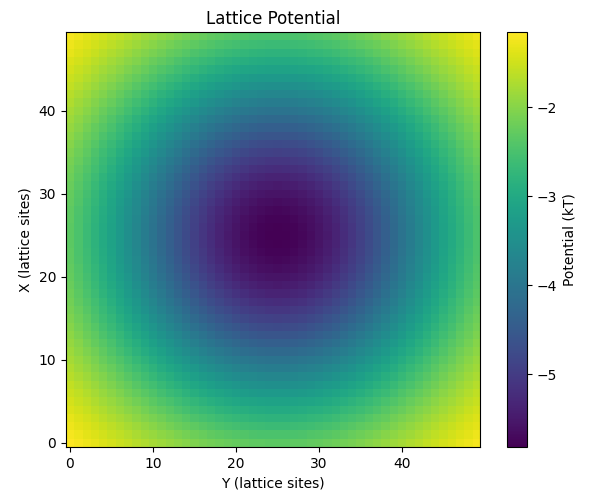

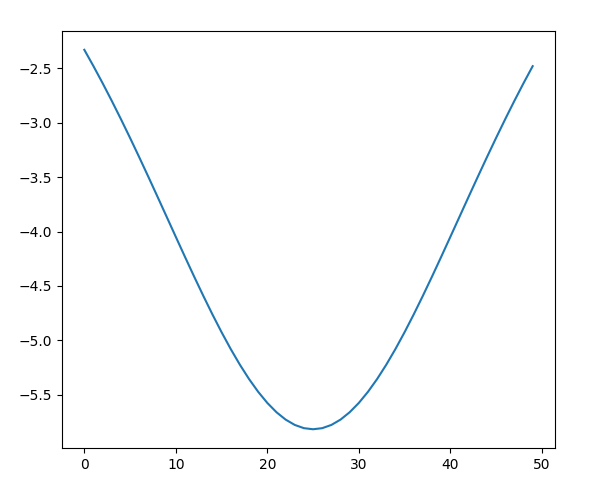

In [15]:
# To plot the lattice potential, just do the following (assuming "Restart Kernel and Clear Outputs" hasn't been used!)

plt.figure(figsize=(6, 5), num=4,clear=True)
plt.imshow(potential_lattice/kT, cmap='viridis', origin='lower')
plt.colorbar(label='Potential (kT)')
plt.title("Lattice Potential")
plt.xlabel("Y (lattice sites)")
plt.ylabel("X (lattice sites)")
plt.tight_layout()
plt.show()

# ... it's also helpful to get a line profile:

plt.figure(figsize=(6, 5), num=5,clear=True)
plt.plot(potential_lattice[:,lattice_dimensions[1]//2]/kT)
plt.show()